# Part 1 : import libreries and data 

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("..//data//heart.csv")

In [5]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


# EDA

<Axes: xlabel='target', ylabel='count'>

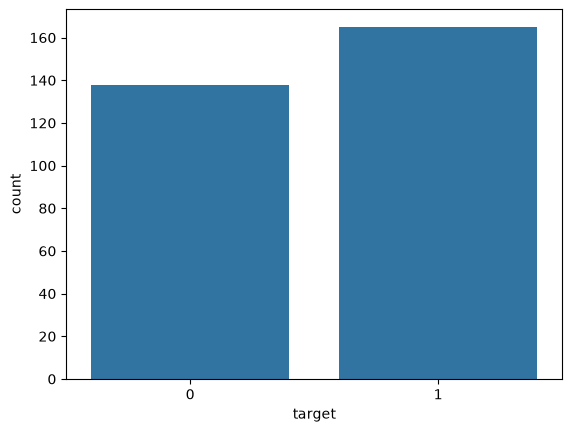

In [8]:
sns.countplot(data=df,x='target')

<Axes: xlabel='sex', ylabel='count'>

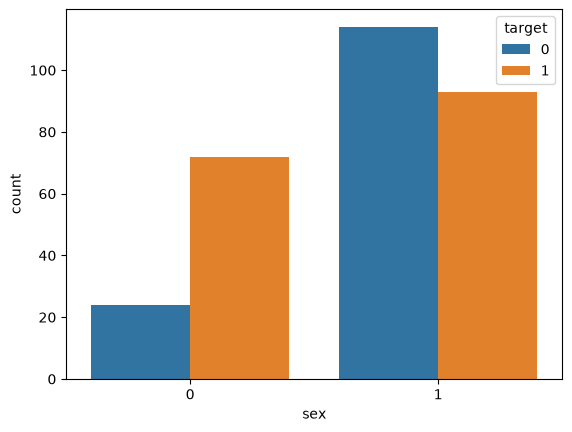

In [10]:
sns.countplot(data=df,x='sex',hue='target')
# 1 for male  0 for female

In [12]:
affected_percentage = df.groupby('sex')['target'].mean() * 100
print("Percentage of patients affected by sex :")
print(affected_percentage.rename({0: 'Female (0)', 1: 'Male (1)'}))

Percentage of patients affected by sex :
sex
Female (0)    75.000000
Male (1)      44.927536
Name: target, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_928\4139350327.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='age', palette=['lightblue', 'lightcoral'])


<Axes: xlabel='target', ylabel='age'>

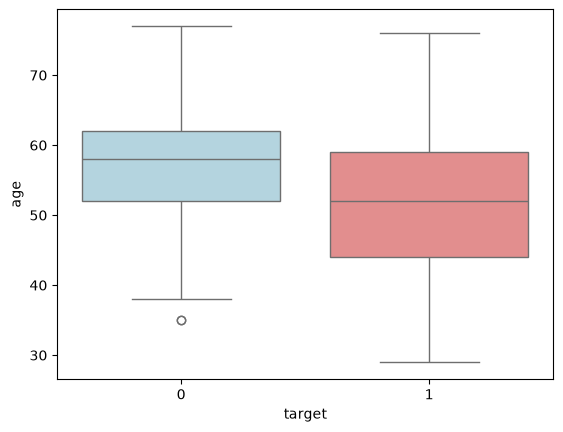

In [17]:
sns.boxplot(data=df, x='target', y='age', palette=['lightblue', 'lightcoral'])

<Axes: xlabel='chol', ylabel='age'>

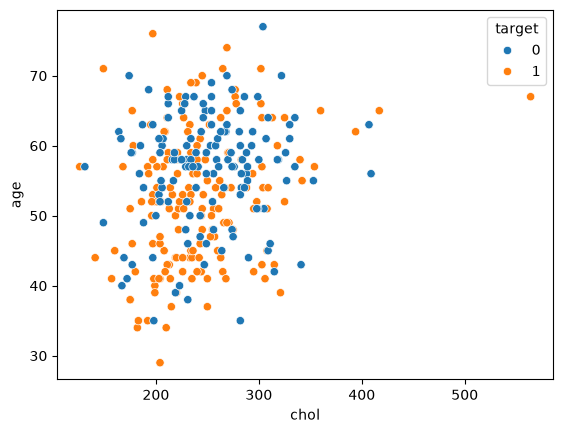

In [19]:
sns.scatterplot(data=df,x='chol',y='age',hue='target')

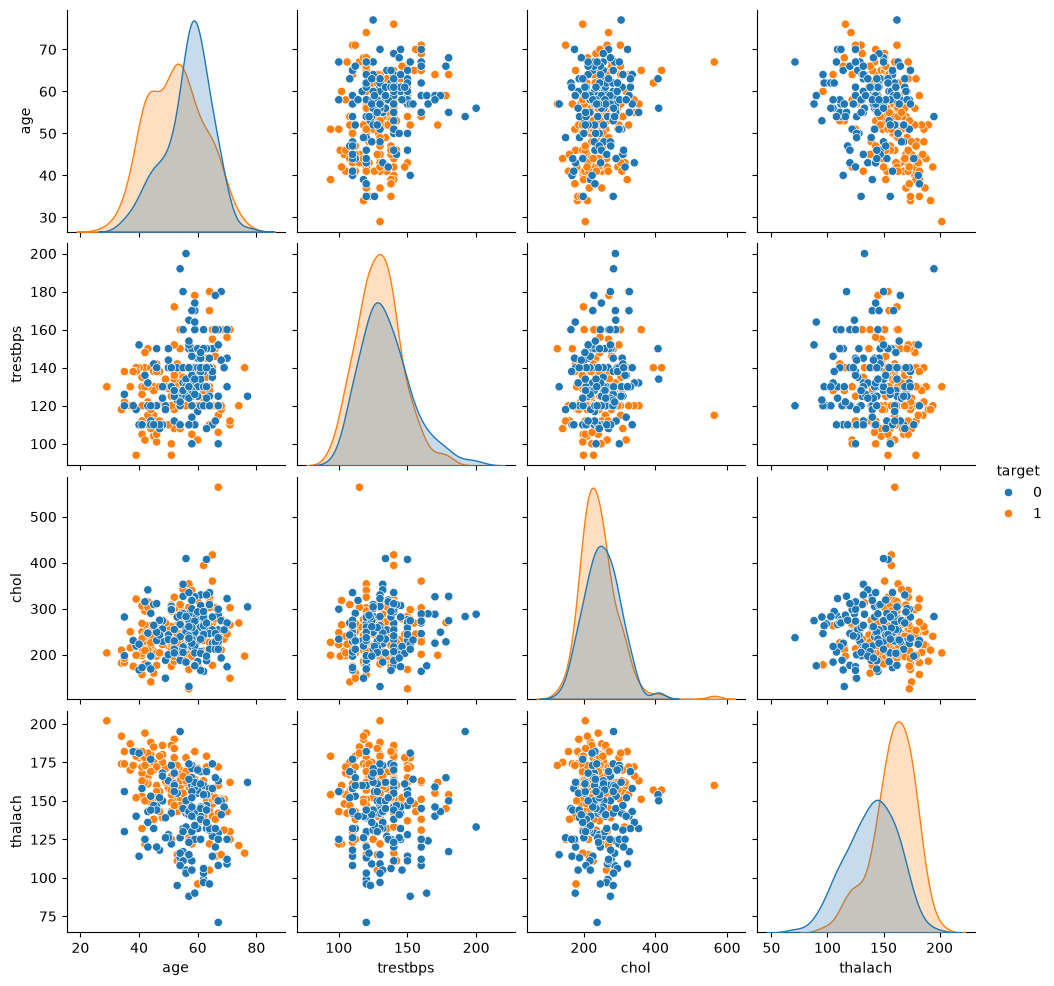

In [20]:
sns.pairplot(df[['age','trestbps', 'chol','thalach','target']],hue='target');

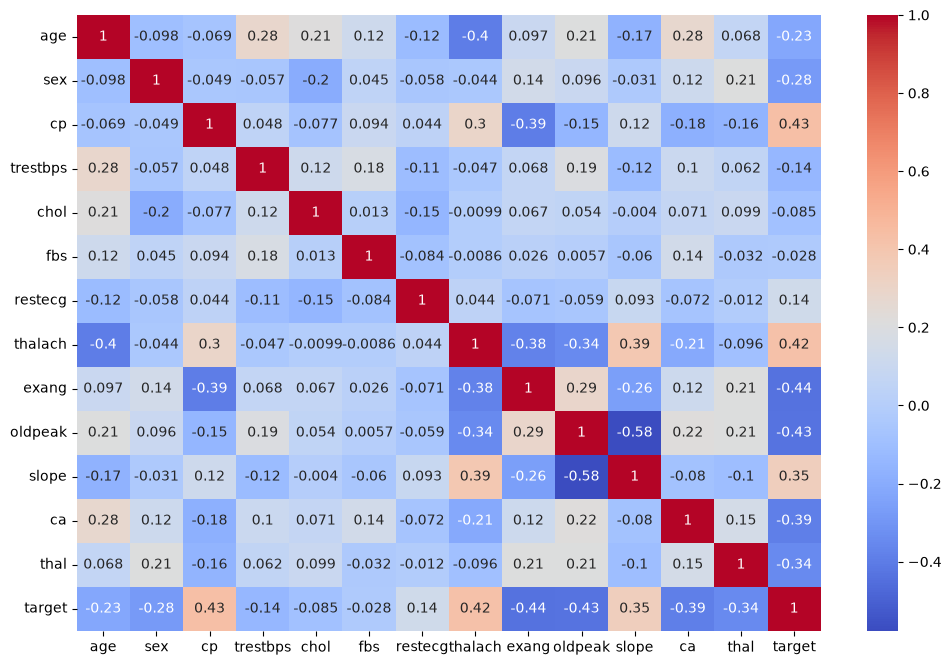

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),cmap='coolwarm',annot=True);

---
---
# Machine Learning

### Train Test - Split

In [23]:
X = df.drop('target',axis=1)

In [24]:
y = df['target']

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=101)

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
scaler = StandardScaler()

In [29]:
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

In [30]:
from sklearn.linear_model import LogisticRegressionCV

In [32]:
#help(LogisticRegressionCV)

In [33]:
log_model = LogisticRegressionCV()

In [34]:
log_model.fit(scaled_X_train,y_train)

,Cs,10
,fit_intercept,True
,cv,None
,dual,False
,penalty,'l2'
,scoring,None
,solver,'lbfgs'
,tol,0.0001
,max_iter,100
,class_weight,None
,n_jobs,None


In [35]:
log_model.get_params()

{'Cs': 10,
 'class_weight': None,
 'cv': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1.0,
 'l1_ratios': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'refit': True,
 'scoring': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0}

In [37]:
log_model.coef_

array([[-0.09624234, -0.39455733,  0.53541263, -0.13845013, -0.0882132 ,
         0.02495565,  0.08083019,  0.29896895, -0.33440044, -0.35252781,
         0.25100118, -0.49732614, -0.37440968]])

In [38]:
from sklearn.metrics import confusion_matrix , classification_report , ConfusionMatrixDisplay

In [39]:
y_pred = log_model.predict(scaled_X_test)

In [40]:
confusion_matrix(y_test,y_pred)

array([[12,  3],
       [ 2, 14]])

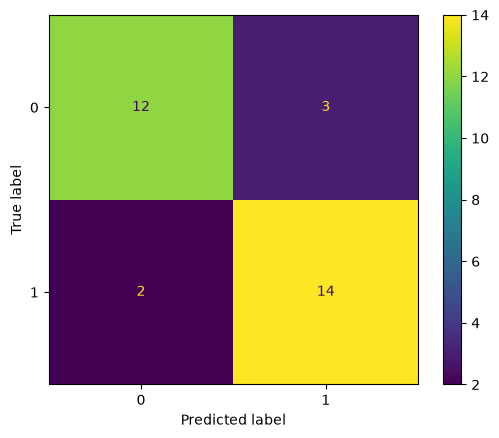

In [42]:
ConfusionMatrixDisplay.from_estimator(log_model,scaled_X_test,y_test)

In [43]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83        15
           1       0.82      0.88      0.85        16

    accuracy                           0.84        31
   macro avg       0.84      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31



In [44]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

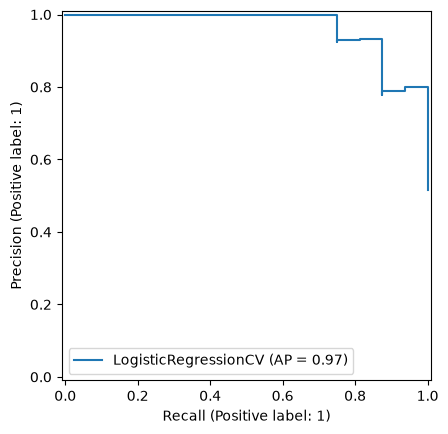

In [45]:
PrecisionRecallDisplay.from_estimator(log_model,scaled_X_test,y_test);

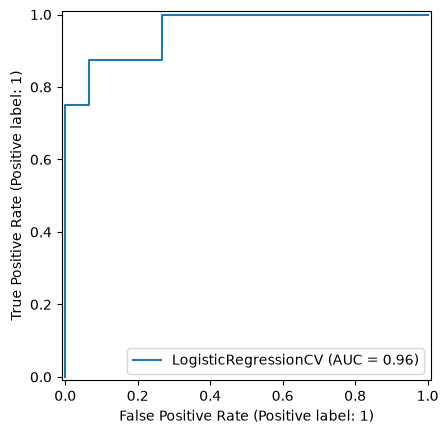

In [46]:
RocCurveDisplay.from_estimator(log_model,scaled_X_test,y_test);

# Test

In [47]:
patient = [[ 54. ,   1. ,   0. , 122. , 286. ,   0. ,   0. , 116. ,   1. ,
          3.2,   1. ,   2. ,   2. ]]

In [48]:
X_test.iloc[-1]

age          54.0
sex           1.0
cp            0.0
trestbps    122.0
chol        286.0
fbs           0.0
restecg       0.0
thalach     116.0
exang         1.0
oldpeak       3.2
slope         1.0
ca            2.0
thal          2.0
Name: 268, dtype: float64